# EDA 04 · Transactions: history

**Question.** Once the current subscription state is known (notebook 03), does the payment *history* add anything, and which few aggregates are worth keeping?

**Input.** Cleaned transactions (`C.clean_transactions`, rules of notebook 02). Payments are records with `is_cancel = 0`; cancellations are counted separately. Records with missing plan fields keep their paid amount but are excluded from plan-length and list-price statistics.

**Candidates**, computed over the whole history and over the last 365 days:

| Group | Features |
|---|---|
| Volume | `n_payments`, `total_paid` |
| Payer tenure | `payer_days` (cutoff − first transaction) |
| Cancellations | `n_cancels`, `days_since_last_cancel` |
| Instability | `n_methods`, `n_method_changes`, `n_plan_lengths`, `n_list_prices`, `auto_share`, `n_auto_switches` |
| Lapses | `n_lapses` (a payment day after the previous expiry), `max_lapse_days`, `total_lapse_days` |
| Price history | `n_free`, `n_discounted` |

**Population.** `fit` customers (notebook 00).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pl.Config.set_tbl_rows(40); pl.Config.set_tbl_width_chars(160)
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.max_colwidth", None)

users = C.load_fit_population()
BASE = users["is_churn"].mean()
txn = C.clean_transactions(users)
st = C.state_block(C.subscription_state(txn, users))
print(f"records: {txn.height:,} | customers: {users.height:,}")

records: 11,334,512 | customers: 744,699


## 1. Building the history features

In [2]:
def history(t: pl.DataFrame, since=None) -> pl.DataFrame:
    if since is not None:
        t = t.filter(pl.col("td") >= pl.lit(since))
    pay = t.filter(pl.col("is_cancel") == 0).sort("msno", "td", "ed", "_ord")
    base = pay.group_by("msno").agg(
        n_payments=pl.len(),
        total_paid=pl.col("actual_amount_paid").sum(),
        first_td=pl.col("td").min(),
        n_methods=pl.col("payment_method_id").n_unique(),
        n_method_changes=(pl.col("payment_method_id") != pl.col("payment_method_id").shift(1)).sum(),
        n_plan_lengths=pl.col("payment_plan_days").drop_nulls().n_unique(),
        n_list_prices=pl.col("plan_list_price").drop_nulls().n_unique(),
        auto_share=pl.col("is_auto_renew").mean(),
        n_auto_switches=(pl.col("is_auto_renew") != pl.col("is_auto_renew").shift(1)).sum(),
        n_free=(pl.col("price_type") == "free").sum(),
        n_discounted=(pl.col("price_type") == "discounted").sum(),
    )
    canc = t.filter(pl.col("is_cancel") == 1).group_by("msno").agg(
        n_cancels=pl.col("td").n_unique(), last_cancel=pl.col("td").max())
    days = (t.group_by("msno", "td").agg(day_expire=pl.col("ed").max(), has_payment=(pl.col("is_cancel") == 0).any())
             .sort("msno", "td")
             .with_columns(prev_expire=pl.col("day_expire").shift(1).over("msno")))
    days = days.with_columns(gap=(pl.col("td") - pl.col("prev_expire")).dt.total_days())
    lapses = days.filter(pl.col("has_payment") & (pl.col("gap") > 0)).group_by("msno").agg(
        n_lapses=pl.len(), max_lapse_days=pl.col("gap").max(), total_lapse_days=pl.col("gap").sum())
    h = (users.select("msno").join(base, on="msno", how="left").join(canc, on="msno", how="left")
              .join(lapses, on="msno", how="left"))
    zero_cols = ["n_payments", "total_paid", "n_methods", "n_plan_lengths", "n_list_prices", "n_free", "n_discounted", "n_cancels", "n_lapses", "max_lapse_days", "total_lapse_days"]
    return h.with_columns(
        *[pl.col(c).fill_null(0) for c in zero_cols],
        n_method_changes=(pl.col("n_method_changes") - 1).clip(lower_bound=0).fill_null(0),
        n_auto_switches=(pl.col("n_auto_switches") - 1).clip(lower_bound=0).fill_null(0),
        payer_days=(pl.lit(C.CUTOFF) - pl.col("first_td")).dt.total_days(),
        days_since_last_cancel=(pl.lit(C.CUTOFF) - pl.col("last_cancel")).dt.total_days(),
    ).drop("first_td", "last_cancel")

hist_all = history(txn)
hist_12m = history(txn, since=C.CUTOFF - pd.Timedelta(days=364))
HIST = [c for c in hist_all.columns if c != "msno"]
df = (st.join(hist_all, on="msno")
        .join(hist_12m.rename({c: f"{c}_12m" for c in HIST}), on="msno"))
df.select(HIST).describe()

statistic,n_payments,total_paid,n_methods,n_method_changes,n_plan_lengths,n_list_prices,auto_share,n_auto_switches,n_free,n_discounted,n_cancels,n_lapses,max_lapse_days,total_lapse_days,payer_days,days_since_last_cancel
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",744699.0,744699.0,744699.0,744699.0,744699.0,744699.0,743090.0,744699.0,744699.0,744699.0,744699.0,744699.0,744699.0,744699.0,743090.0,150647.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,1609.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1609.0,594052.0
"""mean""",14.970884,2045.630883,1.162729,3.7172e9,1.221084,1.300164,0.873864,3.9359e9,0.099302,0.232178,0.246991,2.580743,33.483978,41.458162,484.295392,312.335772
"""std""",8.150321,1213.823835,0.464875,1.4654e9,0.458449,0.590935,0.312466,1.1888e9,0.705652,1.239443,0.546009,5.345563,84.197096,93.449601,243.461881,207.427589
"""min""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",8.0,1043.0,1.0,4.2950e9,1.0,1.0,1.0,4.2950e9,0.0,0.0,0.0,0.0,0.0,0.0,285.0,123.0
"""50%""",15.0,1788.0,1.0,4.2950e9,1.0,1.0,1.0,4.2950e9,0.0,0.0,0.0,0.0,0.0,0.0,508.0,319.0
"""75%""",22.0,3129.0,1.0,4.2950e9,1.0,1.0,1.0,4.2950e9,0.0,0.0,0.0,2.0,31.0,46.0,731.0,461.0
"""max""",244.0,16800.0,8.0,4.2950e9,7.0,9.0,1.0,4.2950e9,244.0,10.0,20.0,51.0,2951.0,2953.0,761.0,761.0


In [3]:
first = txn.group_by("msno").agg(first_td=pl.col("td").min())
early = first.filter(pl.col("first_td") <= pl.date(2015, 1, 31)).height
print(f"history starts on 2015-01-01; customers whose first record is in January 2015: {early:,} "
      f"({early / users.height:.1%}) -> their history is left-censored")

history starts on 2015-01-01; customers whose first record is in January 2015: 233,515 (31.4%) -> their history is left-censored


The transaction log starts on 2015-01-01, so for long-standing customers every "whole history" count is **truncated** at about 25 months. `payer_days` is capped for them, and totals mix customers observed for 2 years with customers observed for 2 months. The 365-day versions put everyone on the same observation window; section 5 compares both.

## 2. Each candidate against churn

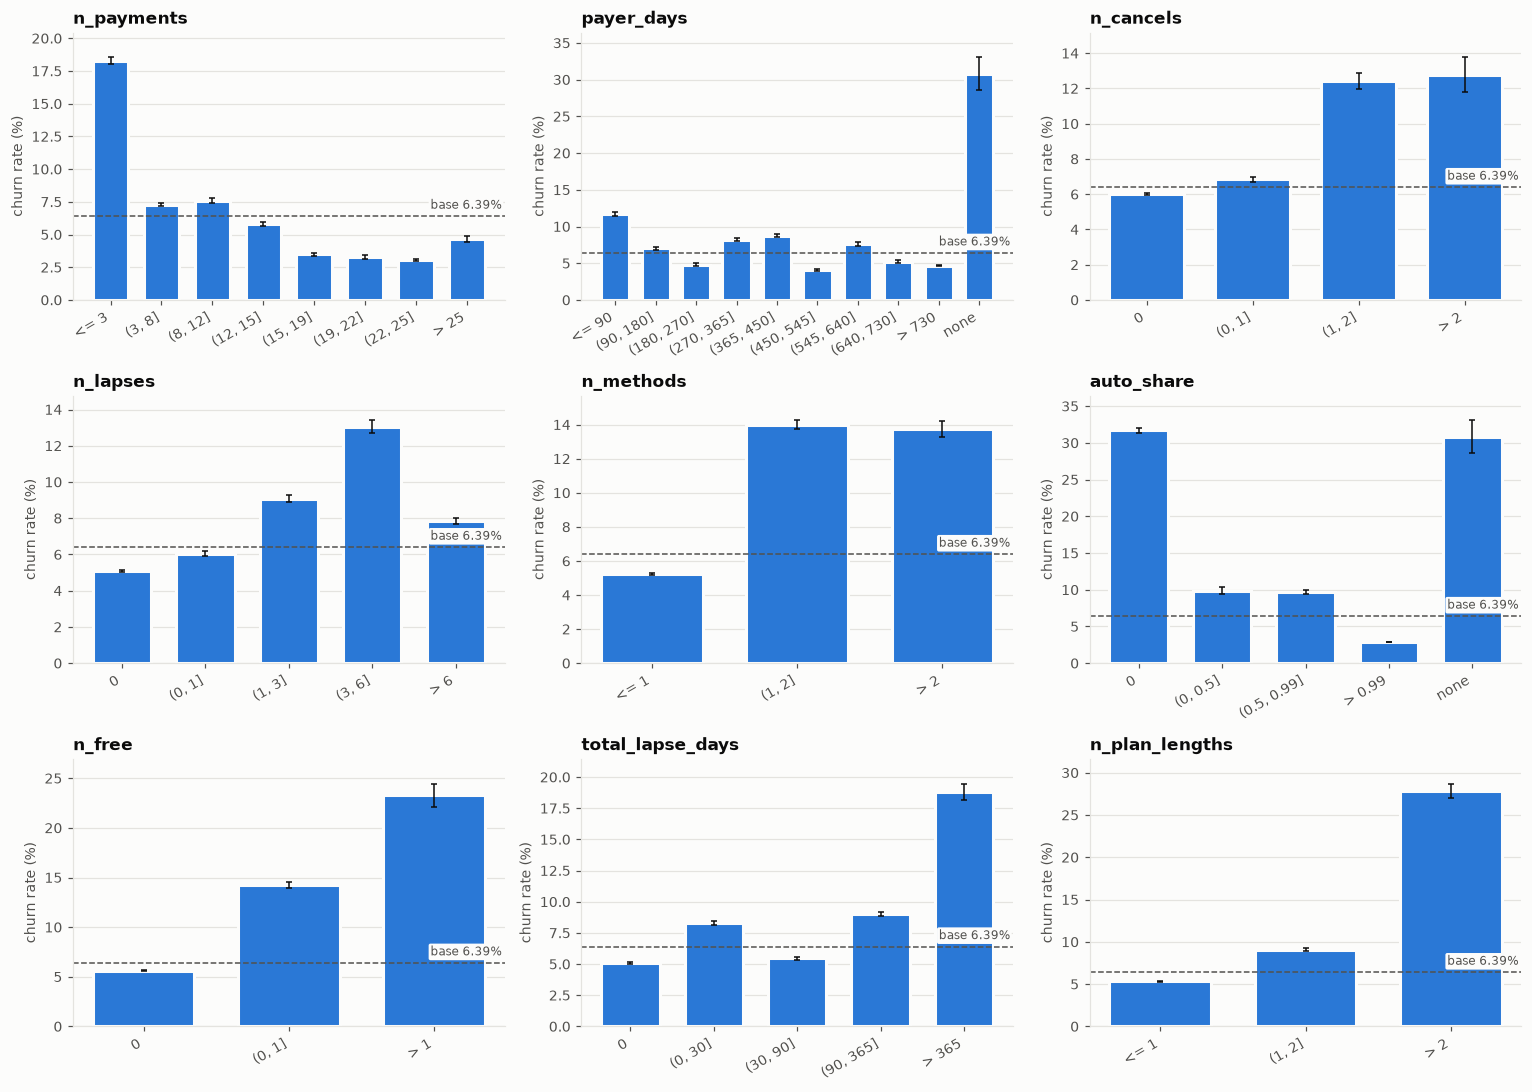

In [4]:
def banded(col, edges):
    """Bands with inclusive upper edges; the last band is open; nulls -> 'none'."""
    labels, lo = [], None
    for e in edges:
        labels.append(f"{e:g}" if lo is None and e == 0 else (f"<= {e:g}" if lo is None else f"({lo:g}, {e:g}]"))
        lo = e
    labels.append(f"> {edges[-1]:g}")
    expr = pl.when(pl.col(col).is_null()).then(pl.lit("none"))
    for e, l in zip(edges, labels):
        expr = expr.when(pl.col(col) <= e).then(pl.lit(l))
    return expr.otherwise(pl.lit(labels[-1])), labels + ["none"]

BANDS = {
    "n_payments": [3, 8, 12, 15, 19, 22, 25],
    "payer_days": [90, 180, 270, 365, 450, 545, 640, 730],
    "n_cancels": [0, 1, 2],
    "n_lapses": [0, 1, 3, 6],
    "n_methods": [1, 2],
    "auto_share": [0, 0.5, 0.99],
    "n_free": [0, 1],
    "total_lapse_days": [0, 30, 90, 365],
    "n_plan_lengths": [1, 2],
}
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, (col, edges) in zip(axes.ravel(), BANDS.items()):
    expr, order = banded(col, edges)
    tbl = C.churn_rate_by(df.with_columns(expr.alias("band")), "band", order=order)
    tbl = tbl[tbl.n > 0].reset_index(drop=True)
    C.plot_churn_rate(tbl, "band", ax=ax, base_rate=BASE, title=col, rotate=30, show_n=False)
    ax.set_xlabel("")
fig.tight_layout(); C.save_fig(fig, "04_history_univariate"); plt.show()


- **Volume and payer tenure** carry the clearest raw signal: customers with 3 or fewer payments churn about 18 %, those with 19+ around 3 %. Both curves have bumps (around 12–15 payments and one year of payer tenure), so the relationship is not smooth; trees handle that better than a single slope.
- Raw, the instability and price-history candidates also look strong: 2+ payment methods 14 %, 3+ plan lengths 28 %, 2+ free periods 23 %, 2+ cancellations 12–13 %, never auto-renewing 32 %. Section 3 shows that most of this is the current state seen again (manual payers and recent cancellers are over-represented in those bands).
- `none` bands are the 0.2 % without any transaction (notebook 00).


## 3. Does the signal survive inside the state?

The question that matters: among customers in the **same** subscription state, does history still separate churners? Churn rate by band, inside the two big states.

In [5]:
def band_within(col, edges, labels):
    b = (pl.when(pl.col(col).is_null()).then(pl.lit("none")))
    for e, l in zip(edges, labels):
        b = b.when(pl.col(col) <= e).then(pl.lit(l))
    b = b.otherwise(pl.lit(labels[-1] if len(labels) > len(edges) else f">{edges[-1]}"))
    d = df.filter(pl.col("state").is_in(["auto-renew", "manual"])).with_columns(band=b)
    t = C.churn_rate_by(d, ["band", "state"])
    order = labels + ["none"]
    p = t.pivot(index="band", columns="state", values="churn_rate").reindex([o for o in order if o in set(t.band)])
    n = t.pivot(index="band", columns="state", values="n").reindex(p.index)
    return p.join(n, rsuffix=" n")

within = {
    "n_payments (all)": band_within("n_payments", [3, 8, 15, 22], ["1-3", "4-8", "9-15", "16-22", "23+"]),
    "n_payments_12m": band_within("n_payments_12m", [3, 8, 11], ["1-3", "4-8", "9-11", "12+"]),
    "n_cancels": band_within("n_cancels", [0, 1], ["0", "1", "2+"]),
    "n_lapses": band_within("n_lapses", [0, 1, 3], ["0", "1", "2-3", "4+"]),
    "n_methods": band_within("n_methods", [1, 2], ["1", "2", "3+"]),
    "n_free": band_within("n_free", [0], ["0", "1+"]),
}
for name, tbl in within.items():
    print(f"\n{name}"); print(tbl.to_string(float_format=lambda v: f"{v:,.4f}"))


n_payments (all)
state  auto-renew  manual  auto-renew n  manual n
band                                             
1-3        0.0343  0.4557         50933     25623
4-8        0.0208  0.3068        105570     21358
9-15       0.0304  0.2472        143452     18532
16-22      0.0151  0.1972        179652     12513
23+        0.0170  0.2187        167551      5057

n_payments_12m
state  auto-renew  manual  auto-renew n  manual n
band                                             
1-3        0.0346  0.4524         53901     32311
4-8        0.0212  0.2854        162269     25478
9-11       0.0198  0.1729         70697     17631
12+        0.0199  0.1888        360291      7663

n_cancels
state  auto-renew  manual  auto-renew n  manual n
band                                             
0          0.0225  0.3170        518039     74407
1          0.0162  0.3109        107652      6716
2+         0.0204  0.3633         21467      1960

n_lapses
state  auto-renew  manual  auto-renew n  manu


- **Inside auto-renew**, history barely moves churn: every band stays between 1.5 % and 4.4 %. The largest contrasts are a past free period (4.4 % vs 2.0 %) and 3+ payment methods (3.7 % vs 2.1 %).
- **Inside manual payment**, history matters a lot, and the direction is telling: manual customers with **more** payments and **more** lapses churn **less** (0 lapses: 50 %; 4+ lapses: 22 %). A manual customer who has lapsed and come back many times is a habitual late renewer; a manual customer with no history of coming back is a new or one-off buyer.
- So history is mainly a tool to rank the manual group, which holds 55 % of the churners.


## 4. Redundancy among the candidates

In [6]:
cand = HIST + [f"{c}_12m" for c in HIST]
sample = df.select(cand).sample(n=200_000, seed=C.SEED).to_pandas()
rho = sample.corr(method="spearman")
pairs = (rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
           .rename("spearman").reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
pairs = pairs.reindex(pairs.spearman.abs().sort_values(ascending=False).index)
print("pairs with |rho| >= 0.85:")
pairs[pairs.spearman.abs() >= 0.85].reset_index(drop=True)

pairs with |rho| >= 0.85:


,a,b,spearman
0,days_since_last_cancel,days_since_last_cancel_12m,1.0000
1,max_lapse_days_12m,total_lapse_days_12m,0.9957
2,max_lapse_days,total_lapse_days,0.9938
3,n_lapses_12m,total_lapse_days_12m,0.9701
4,n_lapses_12m,max_lapse_days_12m,0.9587
5,n_methods,n_method_changes,-0.9584
6,auto_share,auto_share_12m,0.9384
7,total_paid,payer_days,0.9300
8,n_payments,total_paid,0.9265
9,n_payments,payer_days,0.9106


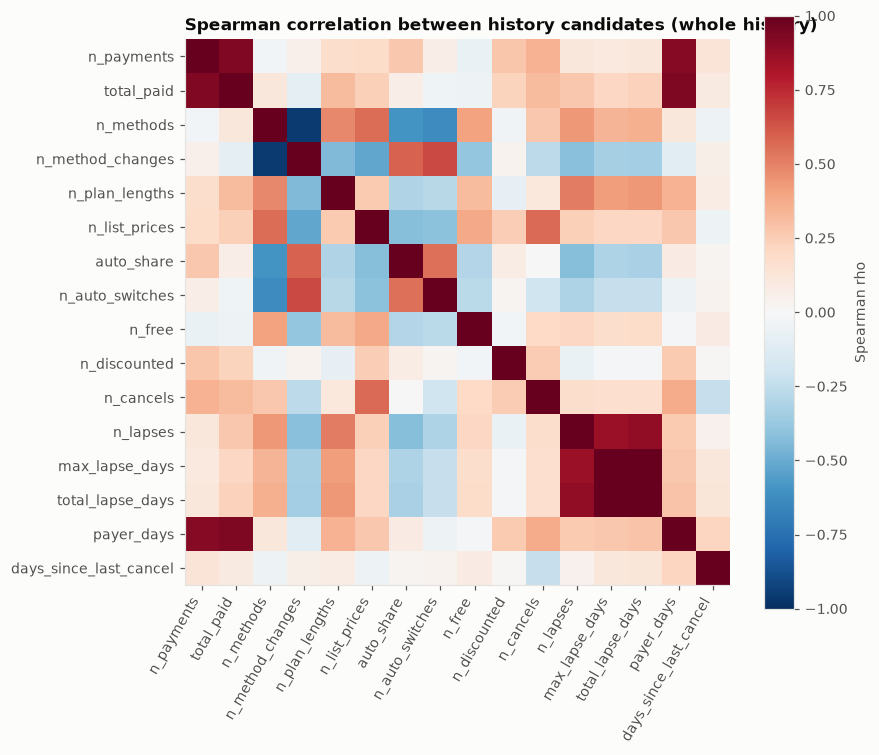

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
r = rho.loc[HIST, HIST]
im = ax.imshow(r.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(HIST)), HIST, rotation=60, ha="right"); ax.set_yticks(range(len(HIST)), HIST)
ax.grid(False); fig.colorbar(im, ax=ax, label="Spearman rho")
ax.set_title("Spearman correlation between history candidates (whole history)", loc="left")
C.save_fig(fig, "04_history_spearman"); plt.show()

## 5. What does history add on top of the state block? (5-fold CV, gradient boosting)

All runs use the notebook-03 state block as categorical inputs. The history features are added as numbers (trees need no bands). For reference, the **current w1 history aggregates** are rebuilt the way the w1 pipeline computes them today (raw zeros, cancellations counted as transactions, cumulative `duration`).

In [8]:
y = df["is_churn"].to_numpy()
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.SEED)

def gbm(num, cat):
    pre = ColumnTransformer([("num", "passthrough", list(num)),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat))])
    return make_pipeline(pre, HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=C.SEED))

def cv(data, num, cat=C.STATE_BLOCK):
    s = cross_validate(gbm(num, cat), data[list(num) + list(cat)], y, cv=CV,
                       scoring=("roc_auc", "average_precision", "neg_log_loss"), n_jobs=5)
    return {"roc_auc": s["test_roc_auc"].mean(), "avg_precision": s["test_average_precision"].mean(),
            "log_loss": -s["test_neg_log_loss"].mean(), "n_features": len(num) + len(cat)}

# current w1 history aggregates (transactions.py), from deduplicated raw records
raw = C.scan_transactions(users).collect(engine="streaming").unique(subset=["msno"] + C.TXN_COLS, keep="first", maintain_order=True)
raw = raw.with_columns(dur=(C.to_date("membership_expire_date") - C.to_date("transaction_date")).dt.total_days())
w1h = raw.group_by("msno").agg(
    is_cancel_change_flag=pl.col("is_cancel").max(), is_auto_renew_change_flag=pl.col("is_auto_renew").max(),
    transaction_count=pl.len(), average_amount_paid=pl.col("actual_amount_paid").mean(),
    average_amount_charged=pl.col("plan_list_price").mean(), average_plan=pl.col("payment_plan_days").mean(),
    n_payment_methods=pl.col("payment_method_id").n_unique(), n_plans=pl.col("payment_plan_days").n_unique(),
    n_list_prices_w1=pl.col("plan_list_price").n_unique(), n_amounts_paid=pl.col("actual_amount_paid").n_unique(),
    duration=pl.col("dur").mean(),
    plan_coverage_ratio=(pl.col("dur") / pl.when(pl.col("payment_plan_days") > 0).then(pl.col("payment_plan_days"))).mean(),
    sum_plan_days=pl.col("payment_plan_days").sum(), sum_list_price=pl.col("plan_list_price").sum(),
    sum_amount_paid=pl.col("actual_amount_paid").sum(), more_than_30=(pl.col("dur") > 30).sum(),
    autorenew_not_cancel=((pl.col("is_auto_renew") == 1) & (pl.col("is_cancel") == 0)).min(),
    max_plan_days=pl.col("payment_plan_days").max(),
).with_columns(difference=pl.col("average_amount_paid") - pl.col("average_amount_charged"))
W1H = [c for c in w1h.columns if c != "msno"]
data = df.join(w1h, on="msno", how="left").to_pandas()
for c in W1H:
    data[c] = data[c].astype(float)

H12 = [f"{c}_12m" for c in HIST]
runs = {
    "state block only": [],
    "+ all candidates (whole history)": HIST,
    "+ all candidates (last 365 days)": H12,
    "+ current w1 history aggregates": W1H,
}
res = pd.DataFrame({k: cv(data, v) for k, v in runs.items()}).T
res

,roc_auc,avg_precision,log_loss,n_features
state block only,0.8568,0.5084,0.1560,7.0000
+ all candidates (whole history),0.8943,0.5684,0.1463,23.0000
+ all candidates (last 365 days),0.8813,0.5618,0.1486,23.0000
+ current w1 history aggregates,0.8919,0.5597,0.1478,26.0000


### 5.1 Which groups carry the gain?

Each candidate group is added alone to the state block (last-365-day versions where they exist, `payer_days` from the whole history because it is a tenure).

In [9]:
GROUPS = {
    "volume": ["n_payments_12m", "total_paid_12m"],
    "payer tenure": ["payer_days"],
    "cancellations": ["n_cancels_12m", "days_since_last_cancel"],
    "instability": ["n_methods_12m", "n_method_changes_12m", "n_plan_lengths_12m", "n_list_prices_12m",
                    "auto_share_12m", "n_auto_switches_12m"],
    "lapses": ["n_lapses_12m", "max_lapse_days_12m", "total_lapse_days_12m"],
    "price history": ["n_free_12m", "n_discounted_12m"],
}
grp = pd.DataFrame({f"+ {g}": cv(data, cols) for g, cols in GROUPS.items()}).T
grp["d_auc_vs_state"] = grp["roc_auc"] - res.loc["state block only", "roc_auc"]
grp["d_ap_vs_state"] = grp["avg_precision"] - res.loc["state block only", "avg_precision"]
grp.sort_values("d_ap_vs_state", ascending=False)

,roc_auc,avg_precision,log_loss,n_features,d_auc_vs_state,d_ap_vs_state
+ lapses,0.8646,0.5496,0.1512,10.0000,0.0078,0.0412
+ payer tenure,0.8890,0.5463,0.1498,8.0000,0.0323,0.0379
+ volume,0.8759,0.5458,0.1506,9.0000,0.0191,0.0373
+ instability,0.8610,0.5202,0.1547,13.0000,0.0042,0.0118
+ price history,0.8571,0.5120,0.1559,9.0000,0.0003,0.0035
+ cancellations,0.8602,0.5119,0.1554,9.0000,0.0034,0.0035



- History adds a lot on top of the state block: ROC AUC 0.857 → 0.894 and AP 0.508 → 0.568 with all candidates.
- **The whole history beats the last 365 days** (AUC 0.894 vs 0.881) despite the left-censoring, because `payer_days` (how long the customer has been paying, capped at 25 months) is the strongest single group (+0.032 AUC). Truncation hurts less than throwing away the long-run information.
- Group by group: **payer tenure**, **volume** and **lapses** carry the gain (+0.037 to +0.041 AP each); instability adds a little; cancellation counts and price history add almost nothing once the state block knows the current cancel / free status.
- The redundancy table confirms what to drop: `total_paid` ≈ `n_payments` ≈ `payer_days` (ρ 0.91–0.93), `max_lapse_days` ≈ `total_lapse_days` (0.99), `n_method_changes` ≈ `n_methods` (|ρ| 0.96).
- The current w1 history aggregates reach a similar level (AUC 0.892, AP 0.560) with 26 columns, several of them broken by the 2015 zeros or the cumulative `duration` (notebook 02). The short list below aims at the same lift with fewer, well-defined columns.


In [10]:
SHORT = ["payer_days", "n_payments", "n_lapses", "total_lapse_days", "n_methods", "auto_share", "n_free"]
MINIMAL = ["payer_days", "n_payments", "n_lapses", "total_lapse_days"]
short = pd.DataFrame({"+ short list (7)": cv(data, SHORT), "+ minimal (4)": cv(data, MINIMAL)}).T
pd.concat([res, short])

,roc_auc,avg_precision,log_loss,n_features
state block only,0.8568,0.5084,0.1560,7.0000
+ all candidates (whole history),0.8943,0.5684,0.1463,23.0000
+ all candidates (last 365 days),0.8813,0.5618,0.1486,23.0000
+ current w1 history aggregates,0.8919,0.5597,0.1478,26.0000
+ short list (7),0.8931,0.5670,0.1466,14.0000
+ minimal (4),0.8929,0.5664,0.1468,11.0000


## 6. Conclusions



- History is the second pillar after the current state: on top of the state block it lifts ROC AUC from 0.857 to 0.893 and AP from 0.508 to 0.566.
- Four well-defined features carry almost all of it: **`payer_days`, `n_payments`, `n_lapses`, `total_lapse_days`** (AUC 0.8929, AP 0.5664, against 0.8943 / 0.5684 with all 16 candidates). Adding `n_methods`, `auto_share` and `n_free` gives +0.0006 AP, within noise.
- Their main job is to rank the **manual** customers: habitual late renewers come back, first-time manual buyers do not.
- Whole history, not a 365-day window, despite the 2015-01-01 truncation.
- The four features replace the 19 current w1 history aggregates, which reach a slightly lower AP (0.560) and include columns broken by the 2015 zeros, the cumulative `duration` and a constant.



In [11]:
decisions = C.write_decisions("04", "Transactions: history", [
    {"finding": "History adds +0.036 AUC / +0.058 AP on top of the state block; 4 features carry almost all of it",
     "decision": "Keep `payer_days`, `n_payments` (payments only, no cancellations), `n_lapses`, `total_lapse_days` (payment day after the previous expiry)",
     "kind": "new feature"},
    {"finding": "Whole history beats a 365-day window (AUC 0.894 vs 0.881) despite truncation at 2015-01-01 (31 % censored)",
     "decision": "Use the whole history; state the censoring as a limitation (`payer_days` capped at ~25 months)",
     "kind": "no action"},
    {"finding": "Inside manual payment more payments / lapses mean less churn (0 lapses 50 %, 4+ lapses 22 %); inside auto-renew history barely matters",
     "decision": "Linear model: interact history bands with `state` (manual vs rest); trees find it alone",
     "kind": "transformation"},
    {"finding": "`total_paid` ~ `n_payments` ~ `payer_days` (rho 0.91-0.93), `max_lapse_days` ~ `total_lapse_days` (0.99), `n_method_changes` ~ `n_methods` (0.96)",
     "decision": "Drop `total_paid`, `max_lapse_days`, `n_method_changes`",
     "kind": "drop"},
    {"finding": "Cancellation counts and price-history counts add ~0 once the state block is known",
     "decision": "Drop `n_cancels`, `days_since_last_cancel`, `n_discounted`; `n_free`, `n_methods`, `auto_share` optional (+0.0006 AP), re-check in notebook 08",
     "kind": "open"},
    {"finding": "Current w1 history aggregates (19 columns) reach AP 0.560 vs 0.566 for the 4 proposed, and several are broken (2015 zeros, cumulative duration, a constant)",
     "decision": "Replace them: drop transaction_count, average_*, sum_*, n_list_prices, n_amounts_paid, n_plans, max_plan_days, is_*_change_flag, autorenew_not_cancel",
     "kind": "drop"},
])
decisions

,finding,decision,kind
0,History adds +0.036 AUC / +0.058 AP on top of the state block; 4 features carry almost all of it,"Keep `payer_days`, `n_payments` (payments only, no cancellations), `n_lapses`, `total_lapse_days` (payment day after the previous expiry)",new feature
1,Whole history beats a 365-day window (AUC 0.894 vs 0.881) despite truncation at 2015-01-01 (31 % censored),Use the whole history; state the censoring as a limitation (`payer_days` capped at ~25 months),no action
2,"Inside manual payment more payments / lapses mean less churn (0 lapses 50 %, 4+ lapses 22 %); inside auto-renew history barely matters",Linear model: interact history bands with `state` (manual vs rest); trees find it alone,transformation
3,"`total_paid` ~ `n_payments` ~ `payer_days` (rho 0.91-0.93), `max_lapse_days` ~ `total_lapse_days` (0.99), `n_method_changes` ~ `n_methods` (0.96)","Drop `total_paid`, `max_lapse_days`, `n_method_changes`",drop
4,Cancellation counts and price-history counts add ~0 once the state block is known,"Drop `n_cancels`, `days_since_last_cancel`, `n_discounted`; `n_free`, `n_methods`, `auto_share` optional (+0.0006 AP), re-check in notebook 08",open
5,"Current w1 history aggregates (19 columns) reach AP 0.560 vs 0.566 for the 4 proposed, and several are broken (2015 zeros, cumulative duration, a constant)","Replace them: drop transaction_count, average_*, sum_*, n_list_prices, n_amounts_paid, n_plans, max_plan_days, is_*_change_flag, autorenew_not_cancel",drop


---
**Previous:** `03_transactions_state.ipynb` · **Next:** `05_user_logs_quality.ipynb`